## AI 헬스케어 첫 번째 미니 프로젝트
흡연 여부 데이터 분석을 통한 건강 인사이트 도출에 오신 여러분 환영합니다!
우리는 흡연 관련 건강 데이터를 분석하여 시각화하고, 다양한 가설을 검증해보는 과정을 함께 할 것입니다.
A부터 Z까지 친절하게 안내해 드릴 예정이니, 천천히 따라해 보세요!

### 🚬 흡연 여부 데이터 분석하기
최근 여러 기관에서는 흡연이 개인의 건강에 미치는 영향을 정확히 파악하고,
이를 기반으로 예방 중심의 건강관리 정책을 수립하려는 노력을 강화하고 있습니다.

하지만 “흡연 여부”를 직접 조사하는 것은 현실적으로 쉽지 않습니다.
이에 따라, 건강검진 데이터를 통해 흡연 여부를 데이터 기반으로 추정하고,
흡연자와 비흡연자 간의 생체·건강 지표 차이를 검증하려는 프로젝트가 시작되었습니다.

여러분은 이 프로젝트의 데이터 분석가이자 AI 엔지니어로 참여하게 되었습니다.
주어진 데이터에는 개인의 건강검진 결과(혈압, 혈당, 콜레스테롤, BMI 등)와 흡연 여부(label = 0 또는 1)가 포함되어 있습니다.

이제 여러분의 역할은 흡연 여부 데이터의 특성을 분석하고 시각화하며, 통계적 검정을 통해 변수 간 관계를 규명하는 것입니다.
시작해봅시다 !

#### 🎯 프로젝트 목표

- 흡연자와 비흡연자 간의 건강 지표 차이 분석
- 주요 변수들의 분포, 상관관계, 통계적 유의성 검증
- 시각화를 통한 데이터 인사이트 도출
- 추후 흡연 여부 예측 모델 개발을 위한 기초 분석 기반 마련



---



## 0. 라이브러리 불러오기
데이터 분석에 필요한 라이브러리를 먼저 불러옵시다! (ex. pandas, matplotlib, seaborn 등)

##### **[TODO] 라이브러리 로딩**
-  `pandas` 라이브러리를 `pd` 라는 별칭으로 불러오세요.
-  `matplotlib` 라이브러리를 `plt` 라는 별칭으로 불러오세요.
-  `seaborn` 라이브러리를 `sns` 라는 별칭으로 불러오세요.

In [ ]:
# 필요한 라이브러리들 불러오기
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import drive
file_path = '/content/smoking_health_data.csv'

print("Pandas 버전:", pd.__version__)
print("\n✨ 모든 라이브러리가 정상적으로 불러와졌습니다!")

Pandas 버전: 2.2.2

✨ 모든 라이브러리가 정상적으로 불러와졌습니다!


In [ ]:
# 코랩(Colab)에서 한글을 지원하는 나눔고딕 폰트를 설치하고 matplotlib에 적용합니다.
!apt-get -qq -y install fonts-nanum > /dev/null
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
fm.fontManager.addfont('/usr/share/fonts/truetype/nanum/NanumGothic.ttf')
plt.rc('font', family='NanumGothic')
plt.rcParams['axes.unicode_minus'] = False
print("한글 폰트 설정 완료! 이제 그래프에 한글을 사용할 수 있습니다.")

한글 폰트 설정 완료! 이제 그래프에 한글을 사용할 수 있습니다.


---
## 1. 데이터 불러오기
모든 데이터 분석의 시작은 '데이터 불러오기' 부터 입니다!

**(예시)**
- csv : pd.read_csv("파일이름. csv")
- txt : pd.read_csv("파일이름. csv", sep="구분자")
- xlsx : pd.read_excel('파일이름.xlsx')
- pickle : pd.read_pickle("파일이름.pkl")

[참고] pickle은 파이썬의 모든 객체를 파일로 저장할 수 있는 방법으로 DataFrame,List,Dict 등 모든 객체 저장 가능
*(특히 sklearn라이브러리를 통해 모델을 학습시키고, 저장할 때 많이 사용됩니다)*

##### **[TODO] 데이터 로딩**
- Pandas의 `read_csv()` 함수를 활용하여 `smoking_health_data.csv` 파일을 `health_data` 변수에 저장하세요.
- `health_data` 데이터프레임의 크기(shape)를 확인하세요.

In [ ]:
# 아래에 실습코드를 작성하고 결과를 확인합니다.
df = pd.read_csv(file_path)
df_cleaned = df.drop_duplicates()
row_count = df.shape[0]
column_count = df.shape[1]

print(f"health_data 행 개수: {row_count} 열 개수: {column_count}")
display(df.head(3))

health_data 행 개수: 7000 열 개수: 18


,ID,나이,키(cm),몸무게(kg),BMI,시력,충치,공복 혈당,혈압,중성 지방,혈청 크레아티닌,콜레스테롤,고밀도지단백,저밀도지단백,헤모글로빈,요 단백,간 효소율,label
0,TRAIN_0000,35,170,70,24.22,1.10,1,98.0,40.0,80.0,1.3,211,75,120,15.9,1,1.53,1
1,TRAIN_0001,40,150,55,24.44,1.00,0,173.0,39.0,104.0,0.6,251,46,184,11.8,1,1.45,0
2,TRAIN_0002,60,170,50,17.30,0.75,0,96.0,40.0,61.0,0.8,144,43,89,15.3,1,1.04,0


---
## 2. 기본 정보 확인 및 데이터 정제
데이터 정제란 ? 결측치, 이상치 등을 제거하여 데이터 분석 결과가 왜곡 되는 문제를 방지하기 위한 정제 과정입니다.

##### **[TODO] 기본 정보 확인하기**
- `health_data` 데이터의 정보를 확인해보세요.
    -   **`info()`**: 각 컬럼의 데이터 타입, Non-null 값 개수 등을 확인합니다.
    -   **`describe()`**: 숫자형 컬럼의 통계 요약 (평균, 표준편차, 최솟값, 최댓값 등)을 확인합니다.
    -   **`head()`**: 데이터의 상위 5행을 확인하여 샘플 데이터를 살펴봅니다.
    -   **`tail()`**: 데이터의 하위 5행을 확인합니다.

In [ ]:
# 아래에 실습코드를 작성하고 결과를 확인합니다.
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7000 entries, 0 to 6999
Data columns (total 18 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   ID        7000 non-null   object 
 1   나이        7000 non-null   int64  
 2   키(cm)     7000 non-null   int64  
 3   몸무게(kg)   7000 non-null   int64  
 4   BMI       7000 non-null   float64
 5   시력        6860 non-null   float64
 6   충치        7000 non-null   int64  
 7   공복 혈당     6860 non-null   float64
 8   혈압        6860 non-null   float64
 9   중성 지방     6860 non-null   float64
 10  혈청 크레아티닌  7000 non-null   float64
 11  콜레스테롤     7000 non-null   int64  
 12  고밀도지단백    7000 non-null   int64  
 13  저밀도지단백    7000 non-null   int64  
 14  헤모글로빈     7000 non-null   float64
 15  요 단백      7000 non-null   int64  
 16  간 효소율     7000 non-null   float64
 17  label     7000 non-null   int64  
dtypes: float64(8), int64(9), object(1)
memory usage: 984.5+ KB


In [ ]:
# 아래에 실습코드를 작성하고 결과를 확인합니다.
print(df.describe().round(2))

            나이    키(cm)  몸무게(kg)      BMI       시력       충치    공복 혈당       혈압  \
count  7000.00  7000.00  7000.00  7000.00  6860.00  7000.00  6860.00  6860.00   
mean     43.97   164.78    65.93    24.14     1.01     0.23    99.31    45.56   
std      12.06     9.17    12.98     3.50     0.43     0.42    21.19     8.83   
min      20.00   135.00    30.00    14.27     0.10     0.00    57.00    14.00   
25%      35.00   160.00    55.00    21.60     0.80     0.00    89.00    40.00   
50%      40.00   165.00    65.00    23.88     1.00     0.00    96.00    45.00   
75%      50.00   170.00    75.00    26.12     1.20     0.00   104.00    50.00   
max      85.00   190.00   130.00    42.45     9.90     1.00   386.00    91.00   

         중성 지방  혈청 크레아티닌    콜레스테롤   고밀도지단백   저밀도지단백    헤모글로빈     요 단백  \
count  6860.00   7000.00  7000.00  7000.00  7000.00  7000.00  7000.00   
mean    127.03      0.88   197.28    57.36   115.35    14.63     1.08   
std      73.22      0.24    36.31    14.51    41.79

In [ ]:
# 아래에 실습코드를 작성하고 결과를 확인합니다.
df.head(3)

,ID,나이,키(cm),몸무게(kg),BMI,시력,충치,공복 혈당,혈압,중성 지방,혈청 크레아티닌,콜레스테롤,고밀도지단백,저밀도지단백,헤모글로빈,요 단백,간 효소율,label
0,TRAIN_0000,35,170,70,24.22,1.10,1,98.0,40.0,80.0,1.3,211,75,120,15.9,1,1.53,1
1,TRAIN_0001,40,150,55,24.44,1.00,0,173.0,39.0,104.0,0.6,251,46,184,11.8,1,1.45,0
2,TRAIN_0002,60,170,50,17.30,0.75,0,96.0,40.0,61.0,0.8,144,43,89,15.3,1,1.04,0


In [ ]:
# 아래에 실습코드를 작성하고 결과를 확인합니다.
df.tail(3)

,ID,나이,키(cm),몸무게(kg),BMI,시력,충치,공복 혈당,혈압,중성 지방,혈청 크레아티닌,콜레스테롤,고밀도지단백,저밀도지단백,헤모글로빈,요 단백,간 효소율,label
6997,TRAIN_6997,40,180,100,30.86,1.20,0,97.0,44.0,87.0,0.9,178,54,107,15.6,1,1.00,0
6998,TRAIN_6998,60,150,55,24.44,0.60,0,89.0,57.0,161.0,0.6,157,49,76,14.4,1,1.00,0
6999,TRAIN_6999,50,165,65,23.88,0.65,0,104.0,47.0,124.0,0.8,251,56,170,13.6,1,0.81,0


##### **[TODO] BMI를 기준으로 체중 상태 구분 컬럼 추가**
- `health_data` 데이터프레임에 'BMI 구간'을 기준으로 체중 상태를 나타내는 새로운 컬럼을 추가하세요.

  - 저체중 (18.5 미만)
  - 정상 (18.5 이상 ~ 22.9 이하)
  - 비만전단계 (23 이상 ~ 24.9 이하)
  - 1단계 비만 (25 이상 ~ 29.9 이하)
  - 2단계 비만 (30 이상 ~ 34.9 이하)
  - 3단계 비만 (35 이상)

In [ ]:
# 아래에 실습코드를 작성하고 결과를 확인합니다.
def calculate_bmi_category(bmi):
    if bmi < 18.5:
        return '저체중'
    elif 18.5 <= bmi <= 22.9:
        return '정상'
    elif 23 <= bmi <= 24.9:
        return '비만 전 단계'
    elif 25 <= bmi <= 29.9:
        return '1단계 비만'
    elif 30 <= bmi <= 34.9:
        return '2단계 비만'
    else:
        return '3단계 비만'

df['BMI 상태'] = df['BMI'].apply(calculate_bmi_category)
print(df[['BMI', 'BMI 상태']].head(5))

     BMI   BMI 상태
0  24.22  비만 전 단계
1  24.44  비만 전 단계
2  17.30      저체중
3  20.00       정상
4  27.06   1단계 비만


##### **[TODO] 나이를 기준으로 나이대 구분 컬럼 추가**
- `health_data` 데이터프레임에 '나이'를 기준으로 나이대를 구분하는 새로운 컬럼을 추가하세요.

  - 20대
  - 30대
  - 40대
  - 50대
  - 60대
  - 70대
  - 70대 초과

In [ ]:
# 아래에 실습코드를 작성하고 결과를 확인합니다.
def calculate_age_group(age):
    if 20 <= age < 30:
        return '20대'
    elif 30 <= age < 40:
        return '30대'
    elif 40 <= age < 50:
        return '40대'
    elif 50 <= age < 60:
        return '50대'
    elif 60 <= age < 70:
        return '60대'
    elif 70 <= age < 80:
        return '70대'
    else:
        return '70대 초과'

df['나이대'] = df['나이'].apply(calculate_age_group)
print(df[['나이', '나이대']].tail())


      나이  나이대
6995  25  20대
6996  60  60대
6997  40  40대
6998  60  60대
6999  50  50대


In [ ]:
#나이대 별 사람 수
age_groupby = df.groupby('나이대').size()
print(age_groupby)

나이대
20대        657
30대       1112
40대       2806
50대       1305
60대        894
70대        194
70대 초과      32
dtype: int64


##### **[TODO] 결측치 확인하기**
- `health_data` 데이터프레임의 모든 컬럼에 대한 결측치(NaN)를 확인하세요.

In [ ]:
df.isnull().sum()

,0
ID,0
나이,0
키(cm),0
몸무게(kg),0
BMI,0
시력,140
충치,0
공복 혈당,140
혈압,140
중성 지방,140


결측치는 분석 결과에 왜곡을 줄 수 있으므로 반드시 확인하고 적절히 처리해야 합니다.  
일반적으로 평균, 중앙값, 최빈값으로 채우지만, 해당 변수의 의미를 고려하여 방법을 선택해야 합니다.

##### **[TODO] 결측치 처리**
- `health_data`의 결측치를 적절한 방법으로 처리하세요.

**(예시)**
- 혈압은 중앙값으로 채우기
- 시력은 최빈값으로 채우기
- 나이대별 중성지방은 그룹 평균으로 채우기
- 공복 혈당은 평균으로 채우기

In [ ]:
# 아래에 실습코드를 작성하고 결과를 확인합니다.
# 혈압, 시력, 공복 혈당, 중성 지방

df['혈압'] = df['혈압'].fillna(df['혈압'].median())
df['시력'] = df['시력'].fillna(df['시력'].mode()[0])
df['공복 혈당'] = df['공복 혈당'].fillna(value = 100)
df['중성 지방'] = df['중성 지방'].fillna(df['중성 지방'].mean())

df.isnull().sum()

,0
ID,0
나이,0
키(cm),0
몸무게(kg),0
BMI,0
시력,0
충치,0
공복 혈당,0
혈압,0
중성 지방,0


---
## 3. 데이터 분석하기

데이터의 형태를 파악하고 다양한 분석 기법을 활용하여, 모델링에 적합한 변수를 선별하는 방법을 알아봅니다.
- 데이터들의 패턴 탐색
- 변수들 간의 관계 파악

##### **[TODO] 데이터 분포 알아보기**
- `health_data`의 주요 변수들에 대해 다양한 시각화(boxplot, histogram, scatterplot 등)를 통해 데이터 분포를 확인하고, 인사이트를 도출하세요.
- 데이터의 형태와 분포를 시각화하면 이상치, 극단값, 데이터 패턴을 쉽게 파악할 수 있습니다!

In [ ]:
# 아래에 실습코드를 작성하고 결과를 확인합니다.
df = df.rename(columns={'label':'흡연여부'})
df.corr(numeric_only=True).round(2)

,나이,키(cm),몸무게(kg),BMI,시력,충치,공복 혈당,혈압,중성 지방,혈청 크레아티닌,콜레스테롤,고밀도지단백,저밀도지단백,헤모글로빈,요 단백,간 효소율,흡연여부
나이,1.00,-0.48,-0.33,-0.07,-0.21,-0.12,0.17,0.17,0.01,-0.09,0.04,0.01,0.03,-0.27,0.05,0.18,-0.17
키(cm),-0.48,1.00,0.68,0.16,0.18,0.08,0.02,0.01,0.15,0.36,-0.07,-0.22,-0.03,0.53,-0.01,-0.27,0.39
몸무게(kg),-0.33,0.68,1.00,0.83,0.14,0.06,0.12,0.12,0.33,0.30,0.03,-0.37,0.05,0.50,0.01,-0.43,0.31
BMI,-0.07,0.16,0.83,1.00,0.05,0.03,0.15,0.16,0.34,0.14,0.09,-0.34,0.08,0.27,0.02,-0.38,0.13
시력,-0.21,0.18,0.14,0.05,1.00,0.03,-0.03,-0.03,0.04,0.06,-0.01,-0.04,-0.02,0.13,-0.02,-0.08,0.07
충치,-0.12,0.08,0.06,0.03,0.03,1.00,-0.01,0.01,0.03,0.03,0.02,-0.01,0.00,0.08,-0.01,-0.06,0.10
공복 혈당,0.17,0.02,0.12,0.15,-0.03,-0.01,1.00,0.09,0.22,0.04,0.00,-0.12,-0.00,0.11,0.12,-0.13,0.11
혈압,0.17,0.01,0.12,0.16,-0.03,0.01,0.09,1.00,0.08,0.02,-0.01,-0.05,-0.02,0.05,0.01,-0.05,0.02
중성 지방,0.01,0.15,0.33,0.34,0.04,0.03,0.22,0.08,1.00,0.11,0.23,-0.42,0.01,0.27,0.04,-0.29,0.25
혈청 크레아티닌,-0.09,0.36,0.30,0.14,0.06,0.03,0.04,0.02,0.11,1.00,-0.01,-0.17,0.03,0.34,0.06,-0.14,0.20


/tmp/ipykernel_1849/3766225327.py:3: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.scatterplot(data=df, x='저밀도지단백', y='콜레스테롤', palette='viridis', alpha=0.6)


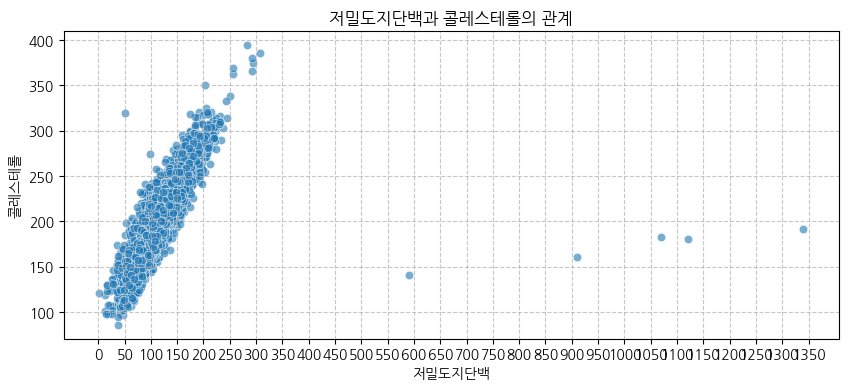

In [ ]:
#저밀도단백질, 콜레스테롤 관계도
plt.figure(figsize=(10, 4))
sns.scatterplot(data=df, x='저밀도지단백', y='콜레스테롤', palette='viridis', alpha=0.6)
plt.title('저밀도지단백과 콜레스테롤의 관계')
plt.xlabel('저밀도지단백')
plt.ylabel('콜레스테롤')
plt.grid(True, linestyle='--', alpha=0.7)
# x축 눈금을 50 단위로 설정
min_ldl = df['저밀도지단백'].min()
max_ldl = df['저밀도지단백'].max()
plt.xticks(range(int(min_ldl // 50) * 50, int(max_ldl // 50 + 1) * 50 + 1, 50))
plt.show()

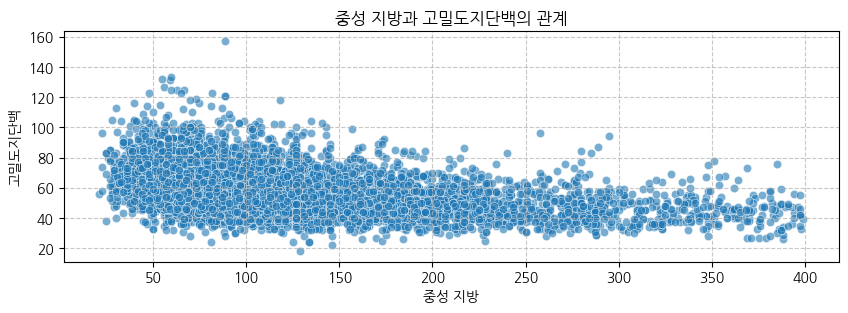

In [ ]:
#중성지방, 고밀도지단백 관계도
plt.figure(figsize=(10, 3))
sns.scatterplot(data=df, x='중성 지방', y='고밀도지단백', alpha=0.6)
plt.title('중성 지방과 고밀도지단백의 관계')
plt.xlabel('중성 지방')
plt.ylabel('고밀도지단백')
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

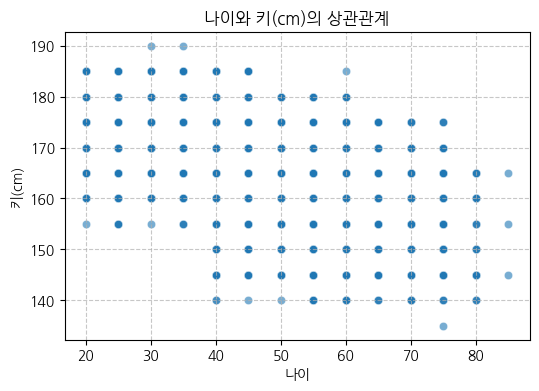

In [ ]:
#키, 나이 관계도
plt.figure(figsize=(6, 4))
sns.scatterplot(data=df, x='나이', y='키(cm)', alpha=0.6)
plt.title('나이와 키(cm)의 상관관계')
plt.xlabel('나이')
plt.ylabel('키(cm)')
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

In [ ]:
# 위 시각화를 통해 알게된 사실을 정리해봅시다.
# 저밀도단백질(LDL), 콜레스테롤 관계도
# 저밀도지단백이 높아질수록 콜레스테롤도 높아지는 것으로 보여진다(양의 상관관계)
# 저밀도지단백은 '나쁜 콜레스테롤'로 콜레스테롤을 혈관으로 운반하는 역할
# 100 미만 - 최상, 129 - 정상, 159 - 경계, 160 ~ - 높음
# 관리가 필요한 사람이 매우 많음
# 콜레스테롤 정상 범위

# 고밀도지단백(HDL), 중성 지방 관계도
# 40 미만 - 낮음, ~ 59 - 보통, 60 ~ - 매우 좋음
# 중성지방 - 섭취한 음식 중 남은 칼로리 지방 세포에 저장해 두는 물질
# 150 미만 - 정상, 199 - 경계, 499 - 높음, 매우 높음
# 음의 상관관계

# 나이, 키 관계도
# 나이가 어릴 수록 키가 크다
# 음의 상관 관계

---
## 4. 가설 수립하기 (최소 3개)
흡연 여부(label)에 따라 각 건강 지표에 통계적으로 유의미한 차이가 있는지 검증하기 위한 가설을 수립합니다.

각 건강 지표(예: BMI, 혈압, 혈당 등)에 대해 최소 3개 이상의 가설을 작성해 보세요.

**(예시)**
- H₀ (귀무가설): BMI- 흡연자와 비흡연자의 평균 BMI는 같다.
- H₁ (대립가설): BMI- 흡연자와 비흡연자의 평균 BMI는 다르다.

##### **[TODO] 3가지 분석 가설 설정**
- 아래 코드 셀에 흡연자와 비흡연자 간의 건강 지표 차이를 검증하기 위한 3가지 가설을 설정하세요.

In [ ]:
# 가설 1. 흡연자와 비흡연자의 헤모글로빈 수치에서 차이가 날 것이다.
# 가설 2. 흡연자의 BMI가 더 높을 것이다.
# 가설 3. 비흡연자의 평균 나이가 더 낮을 것이다.

In [ ]:
smoking_counts = df['흡연여부'].map({0:'비흡연자', 1:'흡연자'}).value_counts()
print(smoking_counts)

흡연여부
비흡연자    4429
흡연자     2571
Name: count, dtype: int64


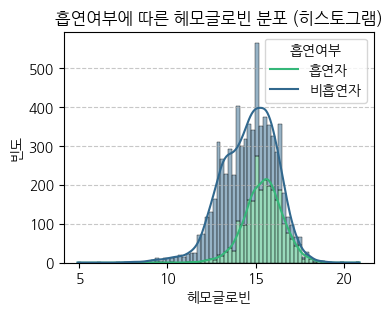

In [ ]:
# 흡연 여부와 헤모글로빈
plt.figure(figsize=(4, 3))
sns.histplot(data=df, x='헤모글로빈', hue='흡연여부', multiple='stack', kde=True, palette='viridis')
plt.title('흡연여부에 따른 헤모글로빈 분포 (히스토그램)')
plt.xlabel('헤모글로빈')
plt.ylabel('빈도')
plt.legend(title='흡연여부', labels=['흡연자', '비흡연자'])
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

/tmp/ipykernel_1849/2771563251.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='흡연여부', y='나이', data=df, palette='viridis')


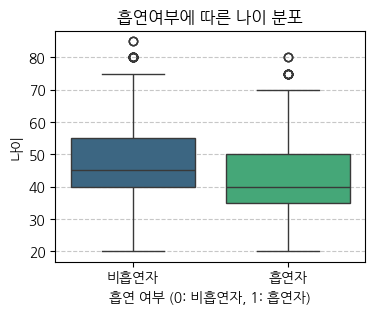

In [ ]:
# 나이와 흡연여부
plt.figure(figsize=(4, 3))
sns.boxplot(x='흡연여부', y='나이', data=df, palette='viridis')
plt.title('흡연여부에 따른 나이 분포')
plt.xlabel('흡연 여부 (0: 비흡연자, 1: 흡연자)')
plt.ylabel('나이')
plt.xticks([0, 1], ['비흡연자', '흡연자'])
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

/tmp/ipykernel_1849/1358907889.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='흡연여부', y='BMI', data=df, palette='viridis')


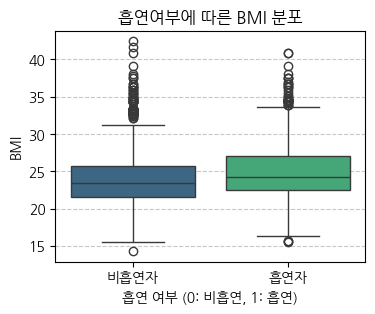

In [ ]:
#흡연 여부와 BMI
plt.figure(figsize=(4, 3))
sns.boxplot(x='흡연여부', y='BMI', data=df, palette='viridis')
plt.title('흡연여부에 따른 BMI 분포')
plt.xlabel('흡연 여부 (0: 비흡연, 1: 흡연)')
plt.ylabel('BMI')
plt.xticks([0, 1], ['비흡연자', '흡연자'])
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

---
## 5. 단변량 분석
단변량 분석은 각 변수(컬럼)의 특성을 개별적으로 탐색하는 과정입니다. 이를 통해 데이터의 전반적인 이해도를 높이고, 이상치나 결측값 등의 문제점을 파악할 수 있습니다.

#### 단변량 분석 목적:
-   **데이터 품질 확인**: 결측값, 이상치 등의 존재 여부를 파악합니다.
-   **변수 유형 이해**: 각 변수가 숫자형인지 범주형인지 구분하고, 데이터의 특성을 파악합니다.
-   **기초 통계량 확인**: 평균, 중앙값, 표준편차 등 핵심 통계치를 통해 데이터의 중심 경향과 퍼짐 정도를 파악합니다.
-   **분포 시각화**: 히스토그램, 박스 플롯 등을 통해 변수의 분포 형태를 시각적으로 확인합니다.
-   **전처리 필요성 판단**: NaN 값 처리, 가변수(Dummy Variable) 생성 등 추가 전처리 필요성을 결정합니다.
-   **비즈니스 인사이트 도출**: 각 변수가 어떤 의미를 가지며, 어떤 비즈니스적 함의를 갖는지 정리합니다.
-   **추가 분석 아이디어 발굴**: 단변량 분석 결과로부터 더 깊이 탐색할 만한 주제나 관계를 도출합니다.

##### **[TODO] 단변량 분석 수행**

다음 코드 셀에서 `health_data` DataFrame의 각 변수에 대해 단변량 분석을 수행해 보세요.

In [ ]:
df.head(1)

,ID,나이,키(cm),몸무게(kg),BMI,시력,충치,공복 혈당,혈압,중성 지방,혈청 크레아티닌,콜레스테롤,고밀도지단백,저밀도지단백,헤모글로빈,요 단백,간 효소율,흡연여부,BMI 상태,나이대
0,TRAIN_0000,35,170,70,24.22,1.1,1,98.0,40.0,80.0,1.3,211,75,120,15.9,1,1.53,1,비만 전 단계,30대


In [ ]:
# 숫자형 변수:
# 나이, 키, 몸무게, BMI, 시력, 공복 혈당, 혈압, 중성 지방, 혈청 크레아티닌, 콜레스테롤, 고밀도지단백, 저밀도지단백, 헤모글로빈, 간 효소율

# 범주형 변수:
# 충치, 요 단백, 흡연여부, BMI 상태



### 나이 (숫자형) 분석

--- 통계 요약 ---
count    7000.00
mean       43.97
std        12.06
min        20.00
25%        35.00
50%        40.00
75%        50.00
max        85.00
Name: 나이, dtype: float64


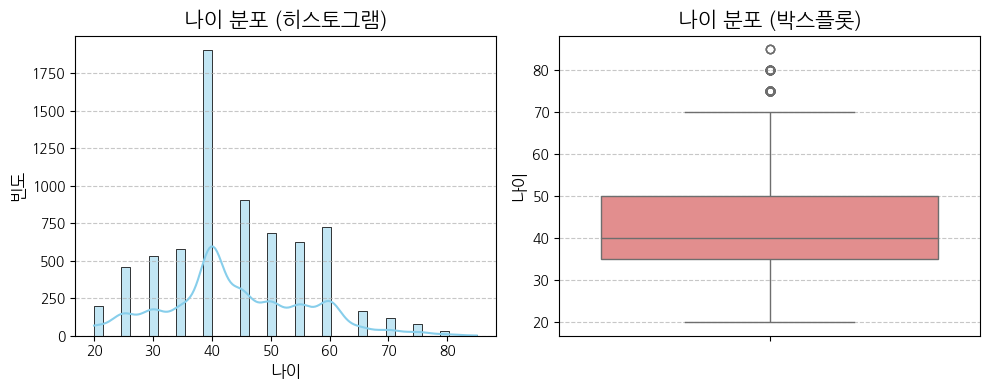



### 키(cm) (숫자형) 분석

--- 통계 요약 ---
count    7000.00
mean      164.78
std         9.17
min       135.00
25%       160.00
50%       165.00
75%       170.00
max       190.00
Name: 키(cm), dtype: float64


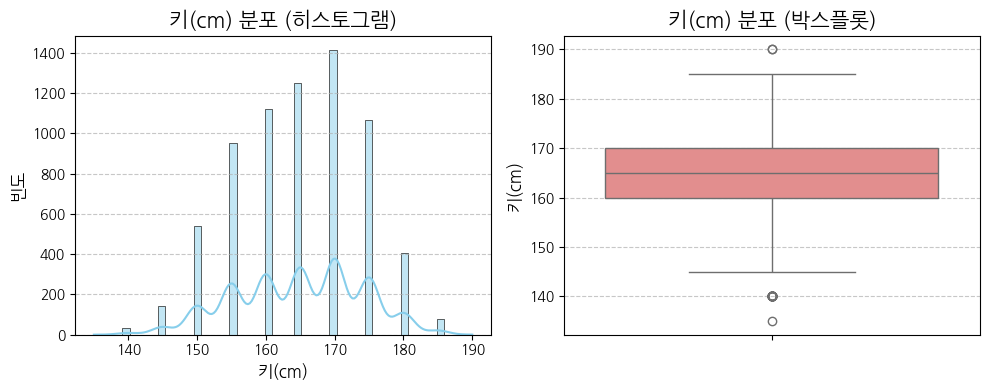



### 몸무게(kg) (숫자형) 분석

--- 통계 요약 ---
count    7000.00
mean       65.93
std        12.98
min        30.00
25%        55.00
50%        65.00
75%        75.00
max       130.00
Name: 몸무게(kg), dtype: float64


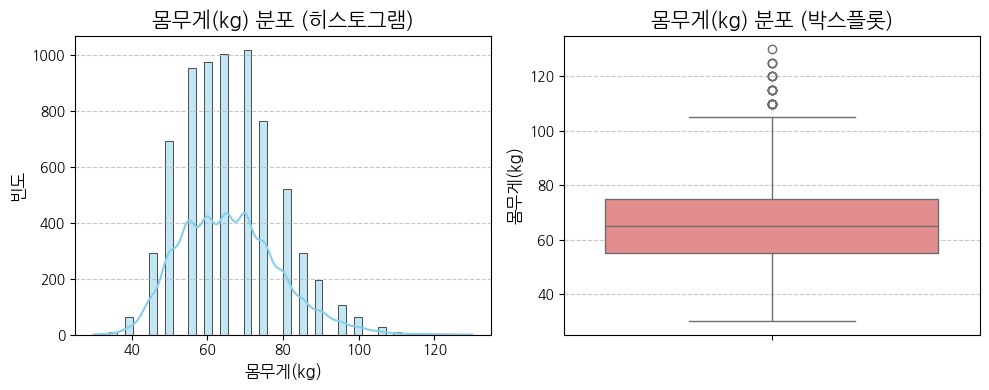



### BMI (숫자형) 분석

--- 통계 요약 ---
count    7000.00
mean       24.14
std         3.50
min        14.27
25%        21.60
50%        23.88
75%        26.12
max        42.45
Name: BMI, dtype: float64


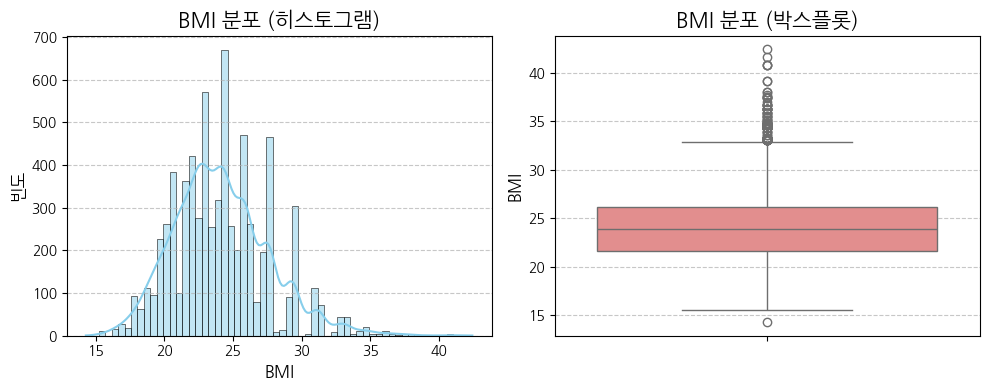



### 시력 (숫자형) 분석

--- 통계 요약 ---
count    7000.00
mean        1.02
std         0.43
min         0.10
25%         0.80
50%         1.00
75%         1.20
max         9.90
Name: 시력, dtype: float64


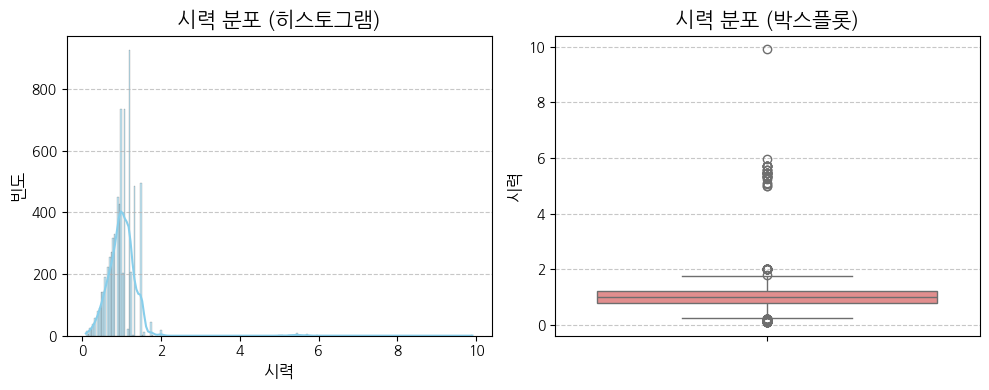



### 충치 (범주형) 분석

--- 빈도수 ---
충치
0    5408
1    1592
Name: count, dtype: int64

--- 비율 ---
충치
0    0.773
1    0.227
Name: proportion, dtype: float64


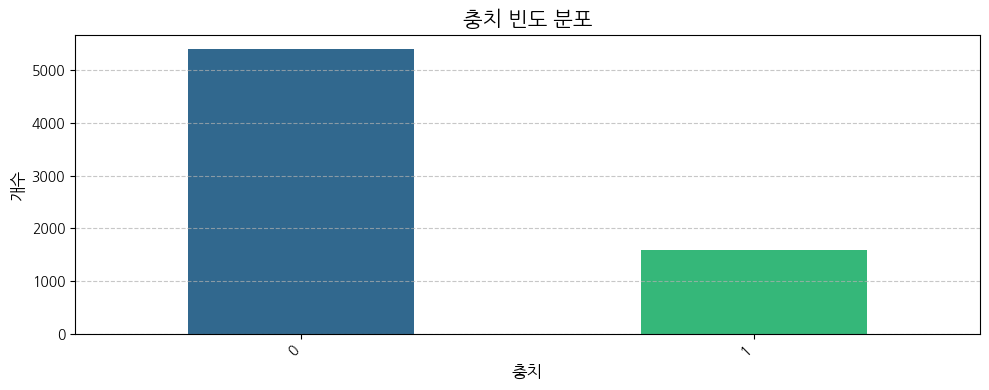



### 공복 혈당 (숫자형) 분석

--- 통계 요약 ---
count    7000.00
mean       99.32
std        20.98
min        57.00
25%        89.00
50%        96.00
75%       103.00
max       386.00
Name: 공복 혈당, dtype: float64


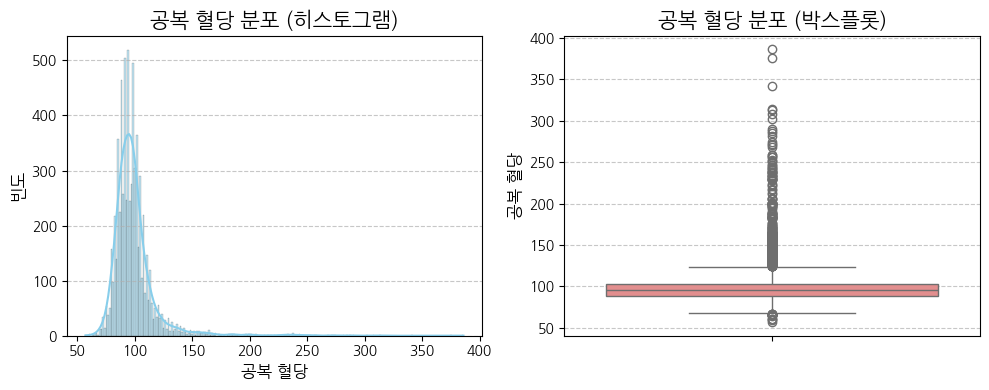



### 혈압 (숫자형) 분석

--- 통계 요약 ---
count    7000.00
mean       45.54
std         8.74
min        14.00
25%        40.00
50%        45.00
75%        50.00
max        91.00
Name: 혈압, dtype: float64


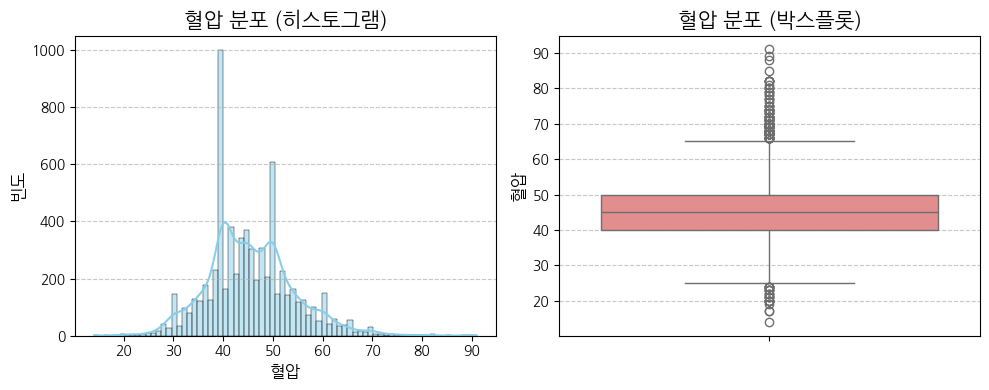



### 중성 지방 (숫자형) 분석

--- 통계 요약 ---
count    7000.00
mean      127.03
std        72.48
min        21.00
25%        74.00
50%       108.00
75%       160.00
max       399.00
Name: 중성 지방, dtype: float64


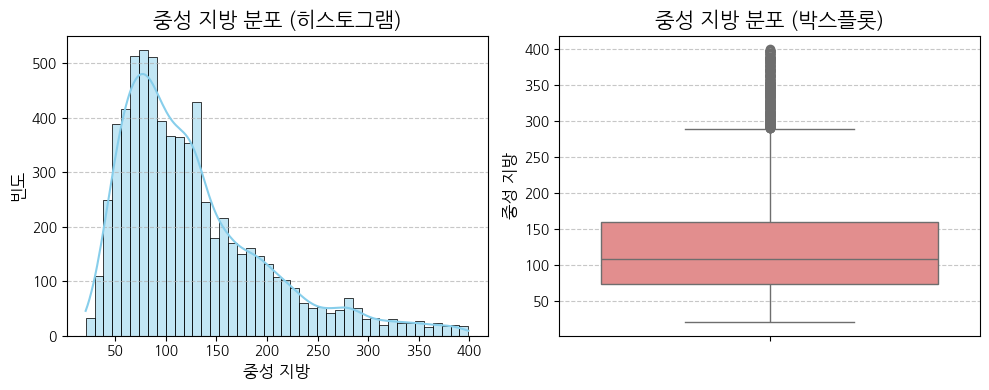



### 혈청 크레아티닌 (숫자형) 분석

--- 통계 요약 ---
count    7000.00
mean        0.88
std         0.24
min         0.10
25%         0.80
50%         0.90
75%         1.00
max        10.00
Name: 혈청 크레아티닌, dtype: float64


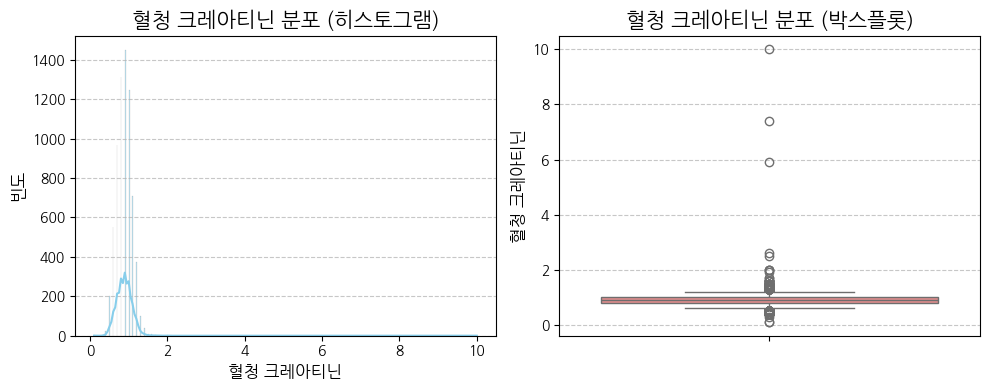



### 콜레스테롤 (숫자형) 분석

--- 통계 요약 ---
count    7000.00
mean      197.28
std        36.31
min        86.00
25%       173.00
50%       195.00
75%       219.00
max       395.00
Name: 콜레스테롤, dtype: float64


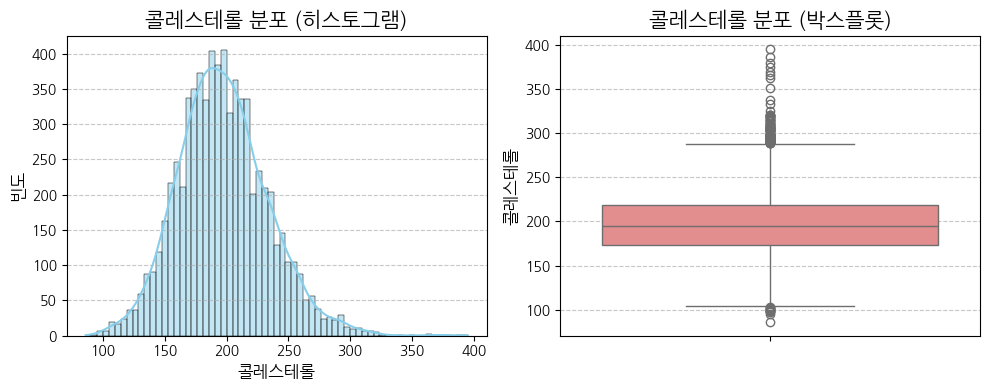



### 고밀도지단백 (숫자형) 분석

--- 통계 요약 ---
count    7000.00
mean       57.36
std        14.51
min        18.00
25%        47.00
50%        55.00
75%        66.00
max       157.00
Name: 고밀도지단백, dtype: float64


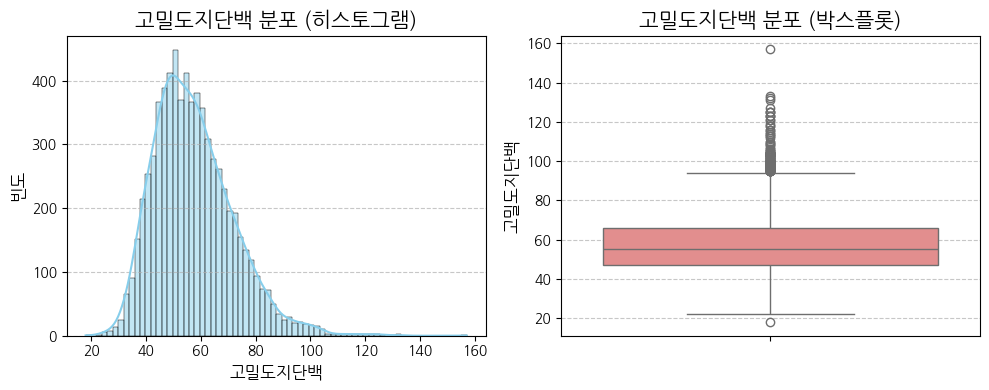



### 저밀도지단백 (숫자형) 분석

--- 통계 요약 ---
count    7000.00
mean      115.35
std        41.79
min         1.00
25%        92.00
50%       113.00
75%       136.00
max      1340.00
Name: 저밀도지단백, dtype: float64


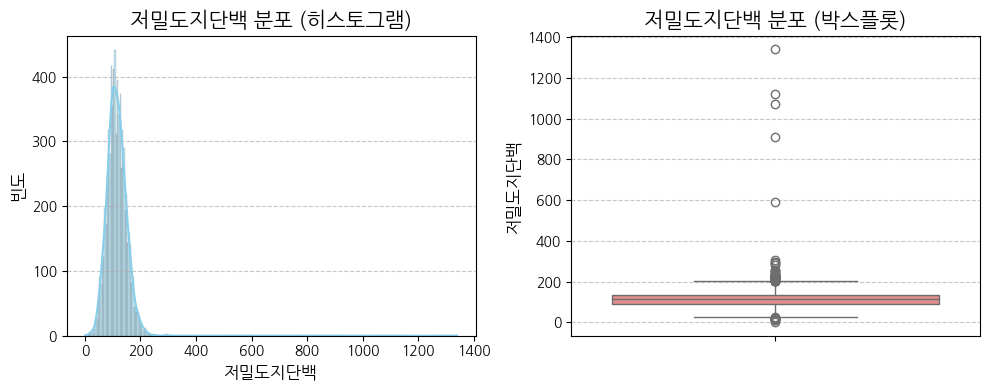



### 헤모글로빈 (숫자형) 분석

--- 통계 요약 ---
count    7000.00
mean       14.63
std         1.54
min         4.90
25%        13.60
50%        14.80
75%        15.70
max        20.90
Name: 헤모글로빈, dtype: float64


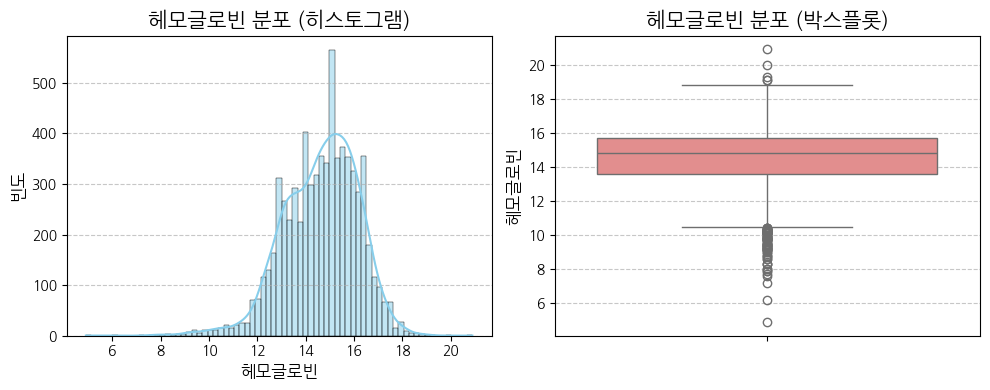



### 요 단백 (범주형) 분석

--- 빈도수 ---
요 단백
1    6618
2     231
3     107
4      34
5      10
Name: count, dtype: int64

--- 비율 ---
요 단백
1    0.945
2    0.033
3    0.015
4    0.005
5    0.001
Name: proportion, dtype: float64


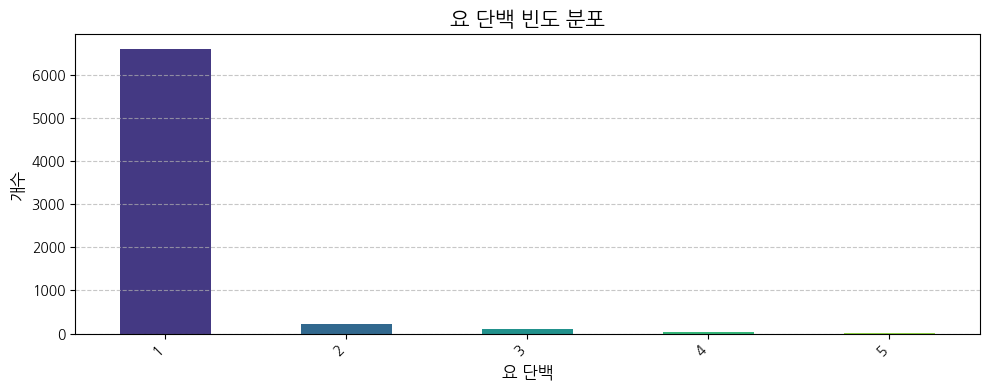



### 간 효소율 (숫자형) 분석

--- 통계 요약 ---
count    7000.00
mean        1.14
std         0.43
min         0.14
25%         0.84
50%         1.10
75%         1.38
max         5.67
Name: 간 효소율, dtype: float64


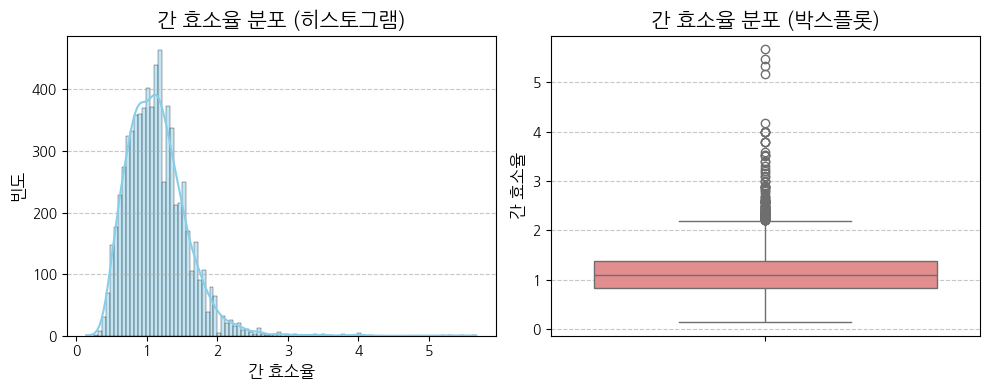



### 흡연여부 (범주형) 분석

--- 빈도수 ---
흡연여부
0    4429
1    2571
Name: count, dtype: int64

--- 비율 ---
흡연여부
0    0.633
1    0.367
Name: proportion, dtype: float64


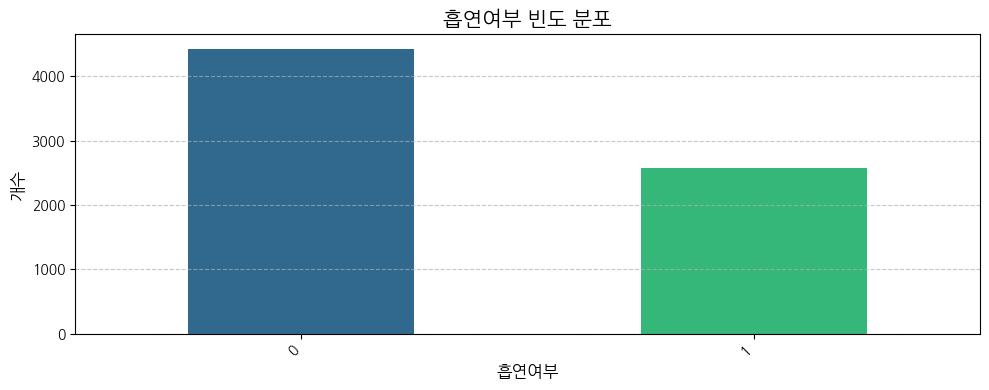



### BMI 상태 (범주형) 분석

--- 빈도수 ---
BMI 상태
정상         2728
1단계 비만     2093
비만 전 단계    1412
2단계 비만      322
저체중         230
3단계 비만      215
Name: count, dtype: int64

--- 비율 ---
BMI 상태
정상         0.390
1단계 비만     0.299
비만 전 단계    0.202
2단계 비만     0.046
저체중        0.033
3단계 비만     0.031
Name: proportion, dtype: float64


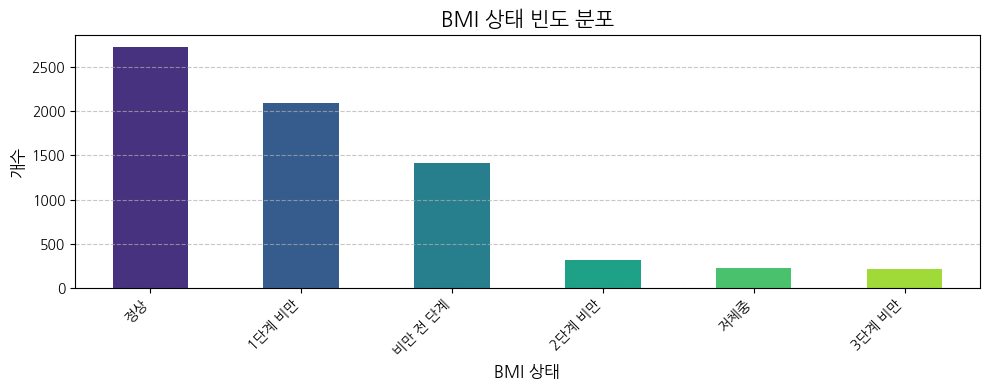



### 나이대 (범주형) 분석

--- 빈도수 ---
나이대
40대       2806
50대       1305
30대       1112
60대        894
20대        657
70대        194
70대 초과      32
Name: count, dtype: int64

--- 비율 ---
나이대
40대       0.401
50대       0.186
30대       0.159
60대       0.128
20대       0.094
70대       0.028
70대 초과    0.005
Name: proportion, dtype: float64


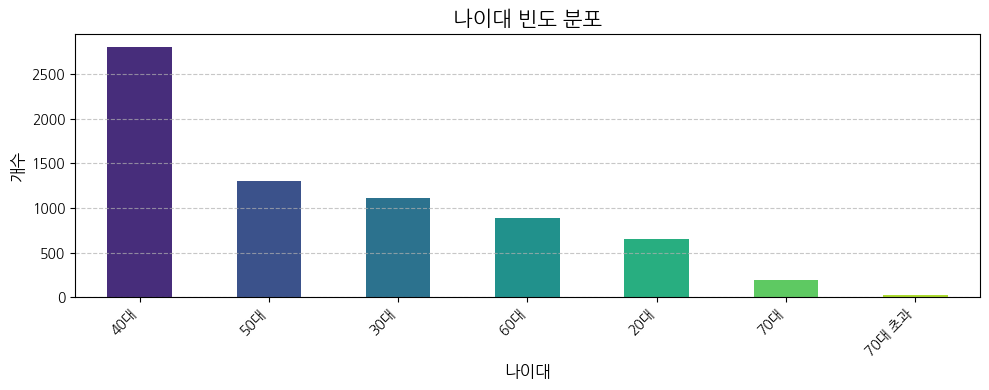

In [ ]:
for col in df.columns:
    if col == 'ID':
        continue

    print(f"\n{'='*50}\n") # 각 컬럼 분석 전에 구분선 추가

    if col in ['충치', '요 단백', '흡연여부'] or df[col].dtype == 'object':
        print(f"### {col} (범주형) 분석")
        print("\n--- 빈도수 ---")
        print(df[col].value_counts())
        print(f"\n--- 비율 ---")
        print(df[col].value_counts(normalize=True).round(3))

        plt.figure(figsize=(10, 4))
        df[col].value_counts().plot(kind='bar', color=sns.color_palette('viridis', n_colors=len(df[col].unique())))
        plt.title(f'{col} 빈도 분포', fontsize=15)
        plt.xlabel(col, fontsize=12)
        plt.ylabel('개수', fontsize=12)
        plt.xticks(rotation=45, ha='right', fontsize=10)
        plt.yticks(fontsize=10)
        plt.grid(axis='y', linestyle='--', alpha=0.7)
        plt.tight_layout()
        plt.show()

    elif df[col].dtype in ['int64', 'float64']:
        print(f"### {col} (숫자형) 분석")
        print("\n--- 통계 요약 ---")
        print(df[col].describe().round(2))

        plt.figure(figsize=(10, 4))

        # 히스토그램
        plt.subplot(1, 2, 1)
        sns.histplot(df[col], kde=True, color='skyblue')
        plt.title(f'{col} 분포 (히스토그램)', fontsize=15)
        plt.xlabel(col, fontsize=12)
        plt.ylabel('빈도', fontsize=12)
        plt.xticks(fontsize=10)
        plt.yticks(fontsize=10)
        plt.grid(axis='y', linestyle='--', alpha=0.7)

        # 박스플롯
        plt.subplot(1, 2, 2)
        sns.boxplot(y=df[col], color='lightcoral')
        plt.title(f'{col} 분포 (박스플롯)', fontsize=15)
        plt.xlabel('', fontsize=12)
        plt.ylabel(col, fontsize=12)
        plt.xticks(fontsize=10)
        plt.yticks(fontsize=10)
        plt.grid(axis='y', linestyle='--', alpha=0.7)

        plt.tight_layout()
        plt.show()

In [ ]:
# 단변량 분석에서 파악한 내용을 정리해보세요.

# 나이: 20 ~ 85세 대상자 가운데 값은 40살이다
# 키: 135 ~ 190cm, 평균 164cm, 표준편차는 10cm 정도이다.
# 몸무게: 30 ~ 130kg, 중간 몸무게는 65kg, 표준편차는 13kg 정도
# BMI: 14 ~ 42, 평균 24, 표준편차는 작다
# 시력: 평균 1.0, 표준편차 적용 0.8~1.2, 시력 9.9가 나온 값이 있어 이상치 존재
# 충치: 23%가 충치
# 공복혈당: 평균 100, 당뇨병 진단 기준 126이상 당뇨병, 아웃라이어가 매우 많음
# 혈압: 평균 45, 최소 혈압 14, 최대 혈압 91(정상 기준 80-120), 추가 조치가 필요함
# 중성지방: 중앙값 108(정상 기준 150미만) 최대 중성 지방 399(매우 위험), 아웃라이어가 매우 많음
# 혈청 크레아티닌: 평균 0.88(정상 기준 0.5 ~ 1.3)
# 콜레스테롤: 중앙값 195(정상 기준 200미만), 최저 86, 최대 395(매우 위험), 재검사 필요함
# 고밀도지단백(HDL): 중앙값 55(정상 기준 40이상), 최저 18(매우 위험), 최고 157(위험)
# 저밀도지단백(LDL): 중앙값 113(정상 기준 130 미만), 최저 1, 최고 1340, 재검사 필요
# 헤모글로빈(Hb): 중앙값 13.8(여성12~15.5, 남성13.5~17.5) 최저 5이하(심각한 빈혈)
# 요단백: 평균 1.08(1이상이면 재검사), 최대 5(신장 질환 의심)
# 간 효소율: 평균 1.14(정상 1에 가까움), 최대 5.67(당뇨 전 단계 ~6.4, 생활습관 개선 필요)
# 흡연율: 흡연자, 비흡연자의 비율은 각각 37%, 63%로 두배 가량 됩니다.
# BMI 상태: 정상: 40%, 1단계 비만: 30%, 비만 전 단계: 20%, 2단계 비만: 5%, 저체중: 3%, 3단계 비만: 3%

---
## 6. 이변량 분석
이변량 분석은 두 변수 간의 관계를 탐색하는 과정입니다. 이를 통해 변수들이 서로 어떻게 영향을 주고받는지 파악하고, 주요 예측 변수를 선별할 수 있습니다.

#### 이변량 분석의 목적

-   **변수 간 관계 탐색**: 원인-결과 관계 또는 상호 연관성을 파악합니다.
-   **주요 영향 요인 도출**: 어떤 변수가 목표 변수(예: 흡연 여부)에 가장 큰 영향을 미 미치는지 확인합니다.
-   **예측 모델 Feature 선별**: 향후 예측 모델 구축 시 중요한 특성(Feature) 후보를 선별합니다.

#### 가설 검정 가이드라인

수립한 가설들을 검정하기 위해 변수 유형에 따라 다음 통계 검정 방법을 활용합니다.

  - 유의수준 : 일반적으로 5% (0.05)를 기준으로 합니다.
  - 숫자형 변수 vs 숫자형 변수 : 상관분석 (Correlation Analysis)
  - 범주형 변수 vs 범주형 변수 : 카이제곱 검정 (Chi-squared Test)
  - 범주형 변수 vs 숫자형 변수 : t-검정 (t-test), 분산 분석 (ANOVA)
  - 숫자형 변수 vs 범주형 변수 : 로지스틱 회귀모형을 통해, 회귀계수의 P-value로 검정을 수행합니다.

##### **[TODO] 이변량 분석 수행**

다음 코드 셀에서 수립한 가설들을 바탕으로 이변량 분석을 수행하고, 결과를 해석해 보세요.

In [ ]:
# 흡연여부(범주형) 헤모글로빈(숫자형)
# 흡연여부(범주형) BMI(숫자형)
# t-검정, 분산 분석

# 나이(숫자형) 흡연여부(범주형)
# 로지스틱, p-value 검정

In [ ]:
# 아래에 실습코드를 작성하고 결과를 확인합니다.
df.corr(numeric_only=True)['흡연여부'].drop('흡연여부').round(2)

,흡연여부
나이,-0.17
키(cm),0.39
몸무게(kg),0.31
BMI,0.13
시력,0.07
충치,0.10
공복 혈당,0.11
혈압,0.02
중성 지방,0.25
혈청 크레아티닌,0.20


In [ ]:
from scipy import stats

In [ ]:
# 흡연여부(label)에 따라 헤모글로빈 데이터 분리
smoker_hemoglobin = df[df['흡연여부'] == 1]['헤모글로빈']
non_smoker_hemoglobin = df[df['흡연여부'] == 0]['헤모글로빈']

# ANOVA 수행
f_statistic_hemo, p_value_hemo = stats.f_oneway(smoker_hemoglobin, non_smoker_hemoglobin)

print(f"흡연여부와 헤모글로빈의 F-통계량: {f_statistic_hemo:.2f}")
print(f"흡연여부와 헤모글로빈의 P-값: {p_value_hemo:.3f}")

if p_value_hemo < 0.05:
    print("\n결론: P-값이 0.05보다 작으므로 귀무가설을 기각합니다. 흡연여부에 따라 헤모글로빈 수치에 통계적으로 유의미한 차이가 있습니다.")
else:
    print("\n결론: P-값이 0.05보다 크므로 귀무가설을 기각할 수 없습니다. 흡연여부에 따라 헤모글로빈 수치에 통계적으로 유의미한 차이가 없습니다.")

흡연여부와 헤모글로빈의 F-통계량: 1348.90
흡연여부와 헤모글로빈의 P-값: 0.000

결론: P-값이 0.05보다 작으므로 귀무가설을 기각합니다. 흡연여부에 따라 헤모글로빈 수치에 통계적으로 유의미한 차이가 있습니다.


In [ ]:
# 흡연 여부와 BMI t-검정 수행
smoker_bmi = df[df['흡연여부'] == 1]['BMI']
non_smoker_bmi = df[df['흡연여부'] == 0]['BMI']
t_statistic_bmi, p_value_t_bmi = stats.ttest_ind(smoker_bmi, non_smoker_bmi, equal_var=True)

print(f"흡연여부와 BMI의 t-통계량: {t_statistic_bmi:.2f}")
print(f"흡연여부와 BMI의 P-값: {p_value_t_bmi:.3f}")

if p_value_t_bmi < 0.05:
    print("\n결론: P-값이 0.05보다 작으므로 귀무가설을 기각합니다. 흡연여부에 따라 BMI에 통계적으로 유의미한 차이가 있습니다.")
else:
    print("\n결론: P-값이 0.05보다 크므로 귀무가설을 기각할 수 없습니다. 흡연여부에 따라 BMI에 통계적으로 유의미한 차이가 없습니다.")

흡연여부와 BMI의 t-통계량: 10.66
흡연여부와 BMI의 P-값: 0.000

결론: P-값이 0.05보다 작으므로 귀무가설을 기각합니다. 흡연여부에 따라 BMI에 통계적으로 유의미한 차이가 있습니다.


In [ ]:
import statsmodels.api as sm

# 종속변수 (흡연여부)와 독립변수 (나이)
Y = df['흡연여부']
X = df['나이']

# 상수항 추가 (회귀 모델의 절편)
X = sm.add_constant(X)

# 로지스틱 회귀 모델 적합
logistic_model = sm.Logit(Y, X)
logistic_result = logistic_model.fit()

# 모델 요약 출력
print(logistic_result.summary())

# 나이의 P-값 확인 및 해석
p_value_age_logistic = logistic_result.pvalues['나이']

print(f"\n나이의 회귀 계수 P-값: {p_value_age_logistic:.3f}")

if p_value_age_logistic < 0.05:
    print("\n결론: P-값이 0.05보다 작으므로 귀무가설을 기각합니다. 나이는 흡연여부에 통계적으로 유의미한 영향을 미칩니다.")
else:
    print("\n결론: P-값이 0.05보다 크므로 귀무가설을 기각할 수 없습니다. 나이는 흡연여부에 통계적으로 유의미한 영향을 미치지 않습니다.")

Optimization terminated successfully.
         Current function value: 0.641859
         Iterations 5
                           Logit Regression Results                           
Dep. Variable:                   흡연여부   No. Observations:                 7000
Model:                          Logit   Df Residuals:                     6998
Method:                           MLE   Df Model:                            1
Date:                Wed, 05 Aug 2026   Pseudo R-squ.:                 0.02378
Time:                        04:02:21   Log-Likelihood:                -4493.0
converged:                       True   LL-Null:                       -4602.5
Covariance Type:            nonrobust   LLR p-value:                 1.562e-49
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.8175      0.097      8.471      0.000       0.628       1.007
나이            -0.0314      0.

In [ ]:
# 이변량 분석에서 파악한 내용을 정리해보세요.

# 흡연 여부와 헤모글로빈 수치에서는 분산 분석을 통해 관계가 있다고 나타난다.

# 흡연 여부와 BMI
# 시각화 그래프에서는 흡연자와 비흡연자의 차이가 크지 않은 것으로 나타났으나 T-검정 결과 유의미한 차이가 있는 것으로 나타났다.

# 나이와 흡연 여부
# 나이는 흡연여부에 통계적으로 유의미한 영향이 있다고 나타난다.

## 7. 변수 간 상관관계 분석

다양한 건강 지표(숫자형 변수)들 간의 상호 관계를 심층적으로 분석합니다. BMI, 혈압, 혈당, 콜레스테롤 등 여러 지표가 어떻게 서로 연관되어 있는지 파악하여, 개인의 건강 상태를 보다 종합적으로 이해하고 향후 예측 모델 설계에 대한 중요한 통찰을 얻을 수 있습니다.

##### **[TODO] 상관계수 확인 및 HeatMap 시각화**
- `health_data`의 수치형 변수들 간의 상관계수를 계산하고, Heatmap으로 시각화하여 변수 간의 관계를 분석하세요.
  - **Heatmap**: 변수 간의 상관관계(Correlation)를 색상으로 쉽게 확인할 수 있는 시각화 방법입니다. 이를 통해 변수 간 관계를 한눈에 비교하고, 분석에 필요한 주요 변수를 파악할 수 있습니다.

#### 상관 계수 해석 기준:
-   **1에 가까울수록 (강한 양의 상관관계)**: 한 변수가 증가할 때 다른 변수도 함께 증가하는 경향이 매우 강합니다.
-   **-1에 가까울수록 (강한 음의 상관관계)**: 한 변수가 증가할 때 다른 변수는 감소하는 경향이 매우 강합니다.
-   **0에 가까울수록 (약한 상관관계)**: 두 변수 사이에 선형적인 관계가 거의 없거나 매우 약합니다.

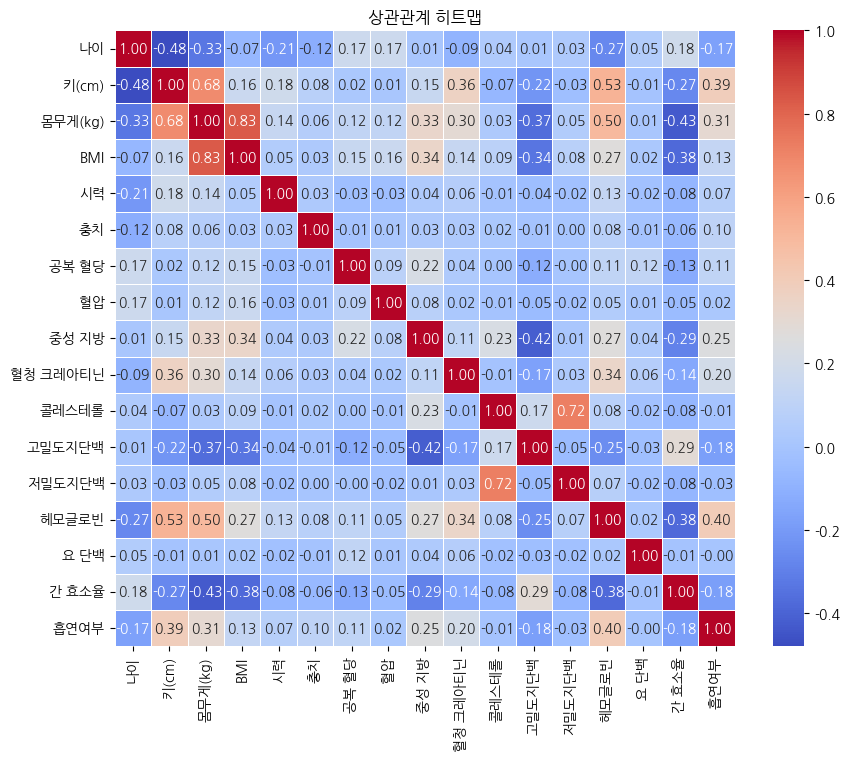

In [ ]:
# 아래에 실습코드를 작성하고 상관계수를 확인 및 시각화 합니다.
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(numeric_only=True).round(2), annot=True, cmap='coolwarm', fmt=".2f", linewidths=.5)
plt.title('상관관계 히트맵', fontsize=12)
plt.show()

In [ ]:
# 강한 관계를 보이는 변수에는 어떤 것이 있나요 ?
# 키 - 몸무게, 몸무게 - BMI, 저밀도지단백 - 콜레스테롤, 키,몸무게 - 헤모글로빈, 나이 - 키

In [ ]:
# 약한 관계를 보이는 변수에는 어떤 것이 있나요 ?
# 흡연여부 - 요단백, 간 효소율 - 요단백, 혈압 - 흡연여부, 몸무게 - 요단백, 저밀도지단백 - 충치

## 8. 결론 및 인사이트 도출

지금까지의 데이터 분석 과정을 통해 흡연 여부와 관련된 건강 지표들 간의 관계를 탐색했습니다. 이제 이 모든 분석 결과를 종합하여 핵심적인 결론과 인사이트를 도출해 보세요.

##### **[TODO] 흡연 여부와 관련성 높은 요인 인사이트 제시**
- 종합 분석 결과와 가설 검정 결과를 바탕으로, 어떤 요인(변수)이 흡연 여부와 관련성이 높은지 인사이트를 제시하세요.

**(예시)**
- 흡연자는 비흡연자에 비해 평균 혈압과 중성지방 수치가 유의하게 높았습니다.(p<0.05)
- 반면, BMI는 유의한 차이가 없었습니다. (p>0.05)
- 따라서 흡연은 대사 관련 지표(혈압, 중성지방)에 더 큰 영향을 미치는 것으로 해석할 수 있습니다.

In [ ]:
# 어떤 요인이 흡연 여부와 관련성이 높을까요 ? 그 이유는?
# 1. 흡연자의 헤모글로빈이 평균 1.28g/dL 만큼 높게 나타났고 분산분석 결과 흡연 여부에 유의미한 영향을 받은 것으로 보입니다.

#    이유: 흡연시 담배 연기 속 일산화탄소가 폐로 들어오는데 헤모글로빈이 산소 대신 일산화탄소(결합력이 200-250배 강함)와 결합하게 되어 몸의 산소 포화도를 낮추게 된다.
#         체네 산소포화도가 낮아지면 콩팥에서 에리스로포이에틴(EPO) 호르몬이 분비되어 골수에서 적혈구 생성을 촉진하여 헤모글로빈 수치가 높아지는 것으로 보여진다.

# 2. 흡연자와 비흡연자의 BMI는 시각화 했을 시 별의미가 없다고 여겨질 정도로 비슷한 양상을 보였으나 T-검정 결과 유의미한 영향이 있는 것으로 나타났습니다.

#    이유: 2015년 기준 한국의료패널을 통한 조사로, 담배값 인상으로 흡연율이 낮아졌을 때, 국민 BMI 수치는 1.30kg/m²만큼, 몸무게는 3.09kg 증가된 것으로 나타났다.
#         흡연을 하면 체네로 들어온 니코틴이 교감신경을 자극해 뇌와 지방세포를 자극하여 기초대사율을 높이고 지방 조직을 태워 에너지를 많이 소비하고 식욕을 억제하는 모습을
#         보여줍니다. 그러나 헤비스모커의 경우 폐활량이 줄어들어 그로인해 운동량도 줄어들면서 오히려 체중이 더 증가하는 모습이 나타나 시각화한 박스 플롯의 모습을 살펴보면
#         큰 차이 없이 비슷한 양상을 보여 줄 수 있으나 유의미한 영향이 있는 것으로 나타난다.


# 3. 비흡연자의 평균 연령이 흡연자의 평균 연령보다 낮을 것이라는 예측과는 달리 비흡연자들의 평균 연령이 통계적으로 높다고 나왔습니다.

#    이유: 지표누리의 현재 흡연율에 대한 자료에 의하면 2010년부터 대한민국의 흡연율은 전체적으로 줄어드는 추세이고
#         남성 흡연자의 비율이 여성 흡연자의 비율보다 약 6배 이상인 것으로 나타난다.
#         담배 가격 인상 등 사회 전반적으로 담배가 건강에 해롭다는 것을 통한 금연율이 높아지고 다양한 금연프로그램이 생겼다는 점에서 담배를 시작하지 않거나
#         금연을 하고자 하는 사람들이 늘었고 청소년들의 담배 흡연율이 낮아져 20대 초반에는 흡연자의 비율이 적어졌으나
#         전자담배 사용량의 급증으로 젊은 층의 흡연자 비율이 높아진 것으로 여겨진다.
#         또 업무 스트레스를 가장 많이 받는 30-50대 특히 40대의 경우 흡연자들의 수가 가장 많은 것으로 나타났다.


#참고 문헌
#담배의 구성성분, 대한폐암학회, https://lungca.or.kr/general/nosmoke/?doc=ingredient&dep_num=2
#EPD 호르몬과 적혈구 생산, 대한내과학학회지, '다양한 빈혈에서의 혈중 적혈구생성인자 분비의 특성'
#흡연과 BMI관계, 한국보건사회연구원, '담뱃값 인상으로 인한 흡연율 감소가 체질량지수와 몸무게에 미치는 영향'
#흡연과 식욕감소, 대한비만협회, '담배를 피우면 다이어트에 도움이 되나요?'
#흡연율 감소, 지표누리, '현재흡연율', https://www.index.go.kr/unify/idx-info.do?idxCd=4237
#청소년과 흡연율, 질병관리청, '청소년건강행태조사', https://www.kdca.go.kr/yhs/
#금연율, 보건복지부 국립정신겅강센터, '금연, 무자르듯 한번에 성공은 힘들다'
#전자담배 사용자, 약사공론, '전자담배 사용 급증… 최근 7년새 궐련형 91%·액상형 73% 증가'
#스트레스와 흡연, 대한직업환경의학회지, '중소규모 사업장의 남성 흡연 근로자에서 직무스트레스와 금연의지와의 관련성'